# Term-deposit subscription prediction — hybrid quantum / classical pipeline

**Goal:** predict `P(y = yes)` for the 100 test customers, once, as continuous probabilities, then rank
them (ties -> lower `customer_id` first). Top 10 move on.

**Judged on:** ROC-AUC, PR-AUC, Precision@10, Recall@10, Brier, log-loss, calibration.

**Model set (fixed by the brief) and what is compared:**

| Group | Members |
|---|---|
| Quantum (exact NumPy statevector simulator, no extra install) | **QFK** - 6-qubit, 2-layer Pauli-ZZ feature map, fidelity-kernel SVM *fused* with an L2-logistic head on `<Z_i>`, `<Z_i Z_j>`; **VQC** - 6-qubit data-re-uploading ansatz with CZ ring (SPSA-trained, classical logistic head) |
| Classical baselines | **LR** (L2 logistic regression), **ET** (ExtraTrees), **RF** (RandomForest), **GB** (GradientBoosting) |
| Hybrid ensembles | every subset of the 6 models that contains **>= 1 quantum and >= 1 classical** member (45 subsets) x 2 meta-learners (`avg` = mean log-odds + Platt, `stk` = L2 logistic stacking on log-odds) = **90 hybrid ensembles**, all built from 5-fold out-of-fold log-odds |
| Validation (train only) | repeated stratified K-fold, 100-row Monte-Carlo hold-outs (mimics the real test), month-grouped CV (distribution shift), 10-fold; tuning happens *inside* every fold (nested) |
| Analysis | hybrid-only ranking, member marginal effects, paired comparisons, stability; final model = best hybrid (or your manual override) |
| Final | fit on all 300 train rows, predict the test file **once** |

## Cell 1 — Setup & configuration

In [15]:
import os, re, glob, time, math, warnings, itertools
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

from joblib import Parallel, delayed
from scipy.linalg import hadamard

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, StratifiedShuffleSplit,
                                     GroupKFold, GridSearchCV, cross_val_predict)
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             make_scorer)

# ----------------------------- user-facing switches -----------------------------
FAST_MODE   = bool(int(os.environ.get("FAST_MODE", "0")))     # True = quick smoke test (fewer folds / smaller grids). Use False for the real run.
SEED        = 42
N_JOBS      = max(1, (os.cpu_count() or 1))   # parallelism over CV folds
TOPK        = 10        # judged cut-off: Precision@10 / Recall@10 on the 100 test customers
TARGET, ID  = "y", "customer_id"

# Optional (only for the PennyLane cross-check in the last cell): !pip install -q pennylane

np.random.seed(SEED)
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("FAST_MODE:", FAST_MODE, "| N_JOBS:", N_JOBS, "| OUT_DIR:", OUT_DIR)

FAST_MODE: False | N_JOBS: 4 | OUT_DIR: /kaggle/working


## Cell 2 — Load data, audit it, and guard against a leaky test file

Files are searched under `/kaggle/input/**` and the working directory. You can force a path with the
environment variables `TRAIN_PATH` / `TEST_PATH`.

In [16]:
def find_file(stem):
    env = os.environ.get(stem.upper() + "_PATH")
    if env and Path(env).exists():
        return env
    pats = []
    for ext in ("xlsx", "xls", "csv"):
        pats += [f"/kaggle/input/**/{stem}.{ext}", f"./{stem}.{ext}", f"/mnt/user-data/uploads/{stem}.{ext}"]
    for p in pats:
        hits = sorted(glob.glob(p, recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"could not find {stem}.(xlsx|csv); set {stem.upper()}_PATH")

def read_any(path):
    return pd.read_csv(path) if str(path).lower().endswith(".csv") else pd.read_excel(path)

TRAIN_PATH = "/kaggle/input/datasets/mayankkumar2177/quant-files/train.xlsx"
TEST_PATH = "/kaggle/input/datasets/mayankkumar2177/quant-files/test.xlsx"

train_raw, test_raw = read_any(TRAIN_PATH), read_any(TEST_PATH)
print("train:", TRAIN_PATH, train_raw.shape, "| test:", TEST_PATH, test_raw.shape)

train_raw[TARGET] = train_raw[TARGET].astype(str).str.strip().str.lower().map({"yes": 1, "no": 0, "1": 1, "0": 0})
assert train_raw[TARGET].notna().all(), "unexpected target values"
assert train_raw[ID].is_unique, "duplicate customer_id in train"
print("positives:", int(train_raw[TARGET].sum()), "of", len(train_raw), f"({train_raw[TARGET].mean():.1%})")
print("missing cells in train:", int(train_raw.isna().sum().sum()))

# ---- test-file audit -------------------------------------------------------------
# A real hold-out test must (a) not share customers with train and (b) have its labels ignored.
overlap   = set(test_raw[ID]) & set(train_raw[ID])
TEST_OK   = True
if TARGET in test_raw.columns:
    print(f"NOTE: test file has a '{TARGET}' column -> it is dropped and NEVER used for fitting or tuning.")
if len(overlap) > 0:
    frac = len(overlap) / len(test_raw)
    print("=" * 90)
    print(f"WARNING: {len(overlap)} of {len(test_raw)} test customer_ids ({frac:.0%}) are also in TRAIN.")
    same = test_raw.drop(columns=[TARGET], errors="ignore").merge(
        train_raw.drop(columns=[TARGET]), how="inner").shape[0]
    print(f"         {same} test rows are exact feature-copies of train rows.")
    print("         Predicting them would be in-sample scoring, not a genuine hold-out prediction.")
    ids_num = train_raw[ID].str.extract(r"(\d+)")[0].astype(int)
    missing = sorted(set(range(1, ids_num.max() + 1)) - set(ids_num))
    print(f"         IDs absent from train in the range 1..{ids_num.max()}: {len(missing)} "
          f"(first few: {missing[:8]}) -> the real test set is probably those customers.")
    print("         Validation below still runs (train only). The FINAL prediction cell will refuse to run")
    print("         until a clean test file is supplied (set TEST_PATH or upload the right file).")
    print("=" * 90)
    TEST_OK = False

feature_cols = [c for c in train_raw.columns if c not in (ID, TARGET)]
X_train = train_raw[feature_cols].reset_index(drop=True)
y_train = train_raw[TARGET].astype(int).values
ids_train = train_raw[ID].values
test_features = test_raw[[c for c in feature_cols if c in test_raw.columns]].copy()
missing_cols = set(feature_cols) - set(test_features.columns)
assert not missing_cols, f"test file lacks columns: {missing_cols}"
print("features:", feature_cols)

train: /kaggle/input/datasets/mayankkumar2177/quant-files/train.xlsx (300, 17) | test: /kaggle/input/datasets/mayankkumar2177/quant-files/test.xlsx (300, 17)
positives: 35 of 300 (11.7%)
missing cells in train: 0
NOTE: test file has a 'y' column -> it is dropped and NEVER used for fitting or tuning.
         300 test rows are exact feature-copies of train rows.
         Predicting them would be in-sample scoring, not a genuine hold-out prediction.
         IDs absent from train in the range 1..400: 100 (first few: [5, 7, 9, 12, 19, 20, 22, 25]) -> the real test set is probably those customers.
         Validation below still runs (train only). The FINAL prediction cell will refuse to run
         until a clean test file is supplied (set TEST_PATH or upload the right file).
features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


## Cell 3 — Quick EDA (train only)

In [17]:
print(train_raw.describe().T[["mean", "std", "min", "max"]].round(2))
for c in ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]:
    g = train_raw.groupby(c)[TARGET].agg(["mean", "count"]).round(3).sort_values("count", ascending=False)
    print(f"\n{c}: subscription rate / n\n", g.T.to_string())

             mean      std     min      max
age         40.79    10.67    22.0     80.0
balance   1695.95  3412.93 -2082.0  27069.0
day         16.71     8.71     1.0     31.0
campaign     2.92     4.00     1.0     50.0
pdays       31.70    86.84    -1.0    385.0
previous     0.44     1.28     0.0      8.0
y            0.12     0.32     0.0      1.0

job: subscription rate / n
 job    management  blue-collar  technician  admin.  services  retired  self-employed  unemployed  entrepreneur  housemaid  student  unknown
mean        0.158        0.106       0.074   0.103     0.118    0.231          0.154       0.083           0.0      0.167      0.0      0.0
count      76.000       66.000      54.000  29.000    17.000   13.000         13.000      12.000          11.0      6.000      2.0      1.0

marital: subscription rate / n
 marital  married  single  divorced
mean         0.1   0.157     0.111
count      190.0  83.000    27.000

education: subscription rate / n
 education  secondary  tert

## Cell 4 — Preprocessing (one pipeline, refit inside every fold)

* `balance` → signed-log + negative flag, `campaign`/`pdays`/`previous` → log, `pdays=-1` → "never contacted" flag
* `education` → ordinal (+ unknown flag), binary yes/no columns → 0/1
* categoricals (`job`, `marital`, `contact`, `month`, `poutcome`) → one-hot, rare levels (<10 rows) pooled into "infrequent"
* numerics standardised. No target information is used here, and no `class_weight`/SMOTE is used anywhere so that
  probabilities stay honest (final calibration is learned out-of-fold).

In [18]:
EDU = {"primary": 0, "secondary": 1, "tertiary": 2}
CAT_COLS = ["job", "marital", "contact", "month", "poutcome"]

class BankFeatures(BaseEstimator, TransformerMixin):
    """Stateless feature engineering (safe to apply identically to train and test)."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = pd.DataFrame(X).copy()
        d = pd.DataFrame(index=X.index)
        d["age"] = X["age"].astype(float)
        bal = X["balance"].astype(float)
        d["log_balance"] = np.sign(bal) * np.log1p(np.abs(bal))
        d["balance_neg"] = (bal < 0).astype(float)
        d["day"] = X["day"].astype(float)
        d["campaign_log"] = np.log1p(X["campaign"].astype(float))
        d["prev_contacted"] = (X["pdays"] >= 0).astype(float)
        d["pdays_log"] = np.log1p(X["pdays"].clip(lower=0).astype(float))
        d["previous_log"] = np.log1p(X["previous"].astype(float))
        d["edu_ord"] = X["education"].map(EDU).astype(float)          # 'unknown' -> NaN -> imputed
        d["edu_unknown"] = X["education"].eq("unknown").astype(float)
        for c in ["default", "housing", "loan"]:
            d[f"{c}_yes"] = X[c].eq("yes").astype(float)
        d["n_loans"] = d["housing_yes"] + d["loan_yes"]
        for c in CAT_COLS:
            d[c] = X[c].astype(str)
        return d

NUM_COLS = ["age", "log_balance", "balance_neg", "day", "campaign_log", "prev_contacted", "pdays_log",
            "previous_log", "edu_ord", "edu_unknown", "default_yes", "housing_yes", "loan_yes", "n_loans"]

def make_preprocessor():
    try:
        ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)
    except TypeError:                                   # older sklearn
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
    ct = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_COLS),
        ("cat", ohe, CAT_COLS)], verbose_feature_names_out=False)
    return Pipeline([("fe", BankFeatures()), ("ct", ct)])

_p = make_preprocessor().fit(X_train)
FEATURE_NAMES = list(_p.named_steps["ct"].get_feature_names_out())
print(len(FEATURE_NAMES), "model features:", FEATURE_NAMES)

42 model features: ['age', 'log_balance', 'balance_neg', 'day', 'campaign_log', 'prev_contacted', 'pdays_log', 'previous_log', 'edu_ord', 'edu_unknown', 'default_yes', 'housing_yes', 'loan_yes', 'n_loans', 'job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_technician', 'job_unemployed', 'job_infrequent_sklearn', 'marital_divorced', 'marital_married', 'marital_single', 'contact_cellular', 'contact_telephone', 'contact_unknown', 'month_aug', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_may', 'month_nov', 'month_infrequent_sklearn', 'poutcome_failure', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']


## Cell 5 — Metrics (the judged ones) and the ranking rule

In [19]:
def id_num(ids):
    return np.array([int(re.sub(r"\D", "", str(i))) for i in ids])

def rank_order(p, ids, decimals=6):
    """Indices from best to worst: higher probability first; ties -> lower customer_id first."""
    return np.lexsort((id_num(ids), -np.round(np.asarray(p, float), decimals)))

def cut_k(n, topk=TOPK):
    return topk if n == 100 else max(1, int(round(0.10 * n)))     # top 10% == "top 10 of 100"

def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def calibration_stats(y, p, n_bins=5):
    """ECE with equal-frequency bins (stable for ~100 rows / ~12% base rate) + calibration slope/intercept."""
    order = np.argsort(p)
    bins = np.array_split(order, n_bins)
    ece = sum(len(b) / len(y) * abs(y[b].mean() - p[b].mean()) for b in bins if len(b))
    try:
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
        slope, intercept = float(lr.coef_[0, 0]), float(lr.intercept_[0])
    except Exception:
        slope = intercept = np.nan
    return ece, slope, intercept

def evaluate(y, p, ids, topk=TOPK):
    y, p = np.asarray(y).astype(int), np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    k = cut_k(len(y), topk)
    order = rank_order(p, ids)
    hits = y[order[:k]].sum()
    out = dict(k=k, precision_at_k=hits / k, recall_at_k=hits / max(1, y.sum()))
    if len(np.unique(y)) == 2:
        out.update(roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p))
    else:
        out.update(roc_auc=np.nan, pr_auc=np.nan)
    out.update(brier=brier_score_loss(y, p), logloss=log_loss(y, p, labels=[0, 1]))
    out["ece"], out["cal_slope"], out["cal_intercept"] = calibration_stats(y, p)
    return out

def tuning_score(y, p):
    """What hyper-parameter searches maximise: mean of ROC-AUC and PR-AUC (ranking quality)."""
    if len(np.unique(y)) < 2:
        return 0.0
    return 0.5 * roc_auc_score(y, p) + 0.5 * average_precision_score(y, p)

try:
    TUNE_SCORER = make_scorer(tuning_score, response_method="predict_proba")
except TypeError:                                       # sklearn < 1.4
    TUNE_SCORER = make_scorer(tuning_score, needs_proba=True)

METRIC_DIRECTION = dict(roc_auc=+1, pr_auc=+1, precision_at_k=+1, recall_at_k=+1,
                        brier=-1, logloss=-1, ece=-1)
print("metrics ready; ranking rule = (-probability rounded to 6 dp, customer_id ascending)")

metrics ready; ranking rule = (-probability rounded to 6 dp, customer_id ascending)


## Cell 6 — Exact NumPy statevector simulator

* **Pauli-ZZ feature map** (`reps` layers): `|0..0> -> [ H^n -> exp(i(Σ u_i Z_i + Σ_{i<j} u_i u_j Z_i Z_j)) ]^reps`,
  `u = bandwidth · x`, `x ∈ [0, π]`. All diagonal gates are folded into one phase vector; `H^n` is a Walsh-Hadamard matrix.
* **Fidelity kernel:** `K(x, x') = |<ψ(x)|ψ(x')>|²` (what a compute-uncompute circuit estimates on hardware).
* **Expectation features:** `<Z_i>` (6) and `<Z_i Z_j>` (15) of the feature-map state.
* Everything is exact (no shot noise). 6 qubits = a 64-dim state, so kernels are instant.

In [20]:
_ZB, _HM = {}, {}
def zbits(n):
    if n not in _ZB:
        idx = np.arange(2 ** n)
        _ZB[n] = 1 - 2 * ((idx[:, None] >> (n - 1 - np.arange(n))) & 1)      # +1 for bit 0, -1 for bit 1 ; (2^n, n)
    return _ZB[n]

def hmat(n):
    if n not in _HM:
        _HM[n] = hadamard(2 ** n) / 2 ** (n / 2)
    return _HM[n]

def zz_map_states(U, reps):
    """U: (N, n) encoded angles (already multiplied by the bandwidth). Returns (N, 2^n) complex statevectors."""
    N, n = U.shape
    Z = zbits(n)
    iu, ju = np.triu_indices(n, 1)
    single = U @ Z.T
    pair = (U[:, iu] * U[:, ju]) @ (Z[:, iu] * Z[:, ju]).T
    phase = np.exp(1j * (single + pair))
    psi = np.full((N, 2 ** n), 1 / math.sqrt(2 ** n), dtype=complex) * phase      # H^n|0>, then phase layer
    H = hmat(n)
    for _ in range(reps - 1):
        psi = (psi @ H) * phase
    return psi

def fidelity_gram(psi_a, psi_b):
    return np.abs(psi_a @ psi_b.conj().T) ** 2

def z_features(psi):
    """<Z_i> and <Z_i Z_j> (i<j) for a batch of states -> (N, n + n(n-1)/2)."""
    n = int(round(math.log2(psi.shape[1])))
    Z = zbits(n)
    iu, ju = np.triu_indices(n, 1)
    prob = np.abs(psi) ** 2
    return np.hstack([prob @ Z, prob @ (Z[:, iu] * Z[:, ju])])

def _selftest():
    n = 3
    Hd, Zm = np.array([[1, 1], [1, -1]]) / np.sqrt(2), np.diag([1, -1])
    op = lambda M, q: np.kron(np.kron(np.eye(2 ** q), M), np.eye(2 ** (n - q - 1)))
    u = np.random.default_rng(0).uniform(0, 2, n)
    H3 = np.eye(1)
    for _ in range(n):
        H3 = np.kron(H3, Hd)
    gens = sum(u[i] * op(Zm, i) for i in range(n)) + sum(u[i] * u[j] * op(Zm, i) @ op(Zm, j)
                                                         for i in range(n) for j in range(i + 1, n))
    D = np.diag(np.exp(1j * np.diag(gens)))
    ref = D @ H3 @ D @ H3 @ np.eye(8)[:, 0]
    mine = zz_map_states(u[None, :], reps=2)[0]
    assert np.allclose(ref, mine), "statevector mismatch"
    f = z_features(mine[None, :])[0]
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    for i in range(n):
        assert np.isclose(f[i], np.real(ref.conj() @ op(Zm, i) @ ref))
    for k, (i, j) in enumerate(pairs):
        assert np.isclose(f[n + k], np.real(ref.conj() @ op(Zm, i) @ op(Zm, j) @ ref))
    print("simulator self-test passed (statevector, <Z_i>, <Z_i Z_j> match brute-force matrices)")
_selftest()

simulator self-test passed (statevector, <Z_i>, <Z_i Z_j> match brute-force matrices)


## Cell 7 — The two quantum models

**1. `QuantumFidelityKernelClassifier` (QFK)** — top-6 features → angles in [0, π] → 2-layer Pauli-ZZ map.
Two read-outs of the *same* quantum state: (a) fidelity-kernel SVM, (b) L2 logistic regression on standardised
`<Z_i>, <Z_i Z_j>`. Bandwidth / C / head-C are tuned in an inner repeated CV on the training rows only; the two
probabilities are fused by averaging log-odds. (`ablation` output available through `component_proba`.)

**2. `DataReuploadingVQC`** — 6 qubits; every layer re-uploads the data (`RY(w_{l,q}·x_q)` with trainable
scaling `w`), then trainable `RZ·RY` per qubit and a CZ ring. Trained with SPSA (2 circuit evaluations per
step regardless of parameter count); a classical logistic head maps `<Z_i>` to a probability (variable-projection:
the head is re-fitted at every loss evaluation).

In [21]:
def top_k_features(X, y, k, seed=0):
    """Pick k of the (standardised) features by |coef| of an L2 logistic regression. Version-agnostic."""
    lr = LogisticRegression(C=0.3, max_iter=2000, random_state=seed).fit(X, y)
    return np.sort(np.argsort(-np.abs(lr.coef_[0]))[:min(k, X.shape[1])])

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class QuantumFidelityKernelClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_qubits=6, reps=2, bw_grid=(0.2, 0.4, 0.8), C_grid=(1.0, 5.0, 25.0),
                 head_C_grid=(0.03, 0.3, 3.0), class_weight="balanced", inner_splits=3, inner_repeats=2, seed=0):
        self.n_qubits, self.reps, self.bw_grid, self.C_grid = n_qubits, reps, bw_grid, C_grid
        self.head_C_grid, self.class_weight = head_C_grid, class_weight
        self.inner_splits, self.inner_repeats, self.seed = inner_splits, inner_repeats, seed

    def _angles(self, X):
        return np.clip(self.scaler_.transform(np.asarray(X, float)[:, self.cols_]), 0, np.pi)

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.cols_ = top_k_features(X, y, self.n_qubits, self.seed)
        self.scaler_ = MinMaxScaler((0, np.pi)).fit(X[:, self.cols_])
        A = self._angles(X)
        splits = list(RepeatedStratifiedKFold(n_splits=self.inner_splits, n_repeats=self.inner_repeats,
                                              random_state=self.seed).split(A, y))
        bk, bh = (-np.inf, None), (-np.inf, None)
        for bw in self.bw_grid:
            psi = zz_map_states(bw * A, self.reps)
            K = fidelity_gram(psi, psi)
            Fz = z_features(psi)
            mu, sd = Fz.mean(0), Fz.std(0) + 1e-9
            Fz = (Fz - mu) / sd
            for C in self.C_grid:                                              # (a) kernel SVM
                sc = []
                for tr, va in splits:
                    m = SVC(C=C, kernel="precomputed", class_weight=self.class_weight).fit(K[np.ix_(tr, tr)], y[tr])
                    sc.append(tuning_score(y[va], m.decision_function(K[np.ix_(va, tr)])))
                if np.mean(sc) > bk[0] + 1e-9:
                    bk = (float(np.mean(sc)), dict(bw=bw, C=C))
            for hc in self.head_C_grid:                                        # (b) <Z>,<ZZ> logistic head
                sc = []
                for tr, va in splits:
                    m = LogisticRegression(C=hc, max_iter=500).fit(Fz[tr], y[tr])
                    sc.append(tuning_score(y[va], m.decision_function(Fz[va])))
                if np.mean(sc) > bh[0] + 1e-9:
                    bh = (float(np.mean(sc)), dict(bw=bw, C=hc, mu=mu, sd=sd))
        self.best_kernel_, self.best_head_ = bk, bh
        # final fits on all training rows
        self.psi_train_ = zz_map_states(bk[1]["bw"] * A, self.reps)
        self.svc_ = SVC(C=bk[1]["C"], kernel="precomputed", class_weight=self.class_weight, probability=True,
                        random_state=self.seed).fit(fidelity_gram(self.psi_train_, self.psi_train_), y)
        Fh = (z_features(zz_map_states(bh[1]["bw"] * A, self.reps)) - bh[1]["mu"]) / bh[1]["sd"]
        self.head_ = LogisticRegression(C=bh[1]["C"], max_iter=500).fit(Fh, y)
        return self

    def component_proba(self, X):
        A = self._angles(X)
        K = fidelity_gram(zz_map_states(self.best_kernel_[1]["bw"] * A, self.reps), self.psi_train_)
        p_kernel = self.svc_.predict_proba(K)[:, 1]
        b = self.best_head_[1]
        F = (z_features(zz_map_states(b["bw"] * A, self.reps)) - b["mu"]) / b["sd"]
        return p_kernel, self.head_.predict_proba(F)[:, 1]

    def predict_proba(self, X):
        p1, p2 = self.component_proba(X)
        p = sigmoid(0.5 * (logit(p1) + logit(p2)))
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class DataReuploadingVQC(BaseEstimator, ClassifierMixin):
    def __init__(self, n_qubits=6, n_layers=3, steps=120, a=0.5, c=0.25, head_C=1.0, seed=0):
        self.n_qubits, self.n_layers, self.steps = n_qubits, n_layers, steps
        self.a, self.c, self.head_C, self.seed = a, c, head_C, seed

    @staticmethod
    def _apply_1q_batch(psi, G, q, n):                       # G: (N, 2, 2) per-sample gate on qubit q
        N = psi.shape[0]
        t = psi.reshape(N, 2 ** q, 2, 2 ** (n - q - 1))
        return np.einsum("nab,nibj->niaj", G, t).reshape(N, -1)

    def _cz_diag(self, n):
        b = (1 - zbits(n)) // 2
        d = np.ones(2 ** n)
        for i, j in {tuple(sorted((i, (i + 1) % n))) for i in range(n)}:      # CZ ring
            if i != j:
                d = d * (1 - 2 * b[:, i] * b[:, j])
        return d

    def _unpack(self, params):
        L, n = self.n_layers, self.n_qubits
        return params[:L * n * 2].reshape(L, n, 2), params[L * n * 2:].reshape(L, n)

    def _features(self, A, params):
        theta, w = self._unpack(params)
        n, N = self.n_qubits, A.shape[0]
        psi = np.zeros((N, 2 ** n), dtype=complex)
        psi[:, 0] = 1.0
        for l in range(self.n_layers):
            for q in range(n):
                ang = w[l, q] * A[:, q]                                        # data re-uploading
                c, s = np.cos(ang / 2), np.sin(ang / 2)
                E = np.zeros((N, 2, 2), dtype=complex)
                E[:, 0, 0], E[:, 0, 1], E[:, 1, 0], E[:, 1, 1] = c, -s, s, c
                ry, rz = theta[l, q]
                T = np.diag([np.exp(-0.5j * rz), np.exp(0.5j * rz)]) @ np.array(
                    [[np.cos(ry / 2), -np.sin(ry / 2)], [np.sin(ry / 2), np.cos(ry / 2)]])
                psi = self._apply_1q_batch(psi, T[None] @ E, q, n)
            psi = psi * self.cz_[None, :]
        return (np.abs(psi) ** 2) @ zbits(n)                                   # <Z_i>

    def _loss(self, params, A, y):
        Fz = self._features(A, params)
        head = LogisticRegression(C=self.head_C, max_iter=300).fit(Fz, y)
        return log_loss(y, np.clip(head.predict_proba(Fz)[:, 1], 1e-6, 1 - 1e-6)), head

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        n, L = self.n_qubits, self.n_layers
        self.cols_ = top_k_features(X, y, n, self.seed)
        self.scaler_ = MinMaxScaler((0, np.pi)).fit(X[:, self.cols_])
        self.cz_ = self._cz_diag(n)
        A = np.clip(self.scaler_.transform(X[:, self.cols_]), 0, np.pi)
        rng = np.random.default_rng(self.seed)
        params = np.concatenate([rng.normal(0, 0.4, L * n * 2), 1.0 + rng.normal(0, 0.1, L * n)])
        best_p, best_l = params.copy(), self._loss(params, A, y)[0]
        A0 = 0.1 * self.steps
        for k in range(self.steps):                                            # SPSA
            ak, ck = self.a / (k + 1 + A0) ** 0.602, self.c / (k + 1) ** 0.101
            delta = rng.choice([-1.0, 1.0], size=params.shape)
            lp, lm = self._loss(params + ck * delta, A, y)[0], self._loss(params - ck * delta, A, y)[0]
            params = params - ak * (lp - lm) / (2 * ck) * delta
            if (k + 1) % 10 == 0 or k == self.steps - 1:
                cur = self._loss(params, A, y)[0]
                if cur < best_l:
                    best_l, best_p = cur, params.copy()
        self.params_, self.train_loss_ = best_p, best_l
        self.head_ = self._loss(best_p, A, y)[1]
        return self

    def predict_proba(self, X):
        A = np.clip(self.scaler_.transform(np.asarray(X, float)[:, self.cols_]), 0, np.pi)
        return self.head_.predict_proba(self._features(A, self.params_))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

# API smoke test on random data
_r = np.random.default_rng(1)
_X, _y = _r.normal(size=(60, 12)), (_r.random(60) < 0.3).astype(int)
for _m in (QuantumFidelityKernelClassifier(bw_grid=(0.3,), C_grid=(1,), head_C_grid=(0.3,)), DataReuploadingVQC(steps=5)):
    assert _m.fit(_X, _y).predict_proba(_X).shape == (60, 2)
print("quantum classifiers: API smoke test OK")

quantum classifiers: API smoke test OK


## Cell 8 — Classical baselines, model registry, and the hybrid-combination ensemble engine

Members: `QFK`, `VQC` (quantum) and `LR`, `ET`, `RF`, `GB` (classical).

`HybridEnsembleSystem.fit` (run inside every validation fold, on that fold's training rows only):
1. fit the preprocessor; 2. obtain 5-fold **out-of-fold** probabilities for every member (tuned members tune themselves in an inner loop) → log-odds matrix `Z`;
3. for **every subset with >= 1 quantum and >= 1 classical member** fit two cheap meta-learners on the OOF log-odds:
   * `avg|...` — mean log-odds of the members → 2-parameter Platt scaling (very low variance),
   * `stk|...` — L2 logistic regression on the members' log-odds (learns weights);
4. refit all members on the full training rows.

`predict_all` returns the test probabilities of every member **and** every hybrid ensemble, so one CV pass compares everything.

In [22]:
CODE = dict(qfk="QFK", vqc="VQC", lr_l2="LR", extra_trees="ET", random_forest="RF", grad_boost="GB")
QUANTUM = ["qfk", "vqc"]
CLASSICAL = ["lr_l2", "extra_trees", "random_forest", "grad_boost"]

def build_base_models(seed=SEED, fast=FAST_MODE):
    skf3 = StratifiedKFold(3, shuffle=True, random_state=seed)
    n_trees = 200 if fast else 500
    return {
        "lr_l2": GridSearchCV(LogisticRegression(max_iter=3000), {"C": [0.01, 0.03, 0.1, 0.3, 1.0]},
                              scoring=TUNE_SCORER, cv=skf3),
        "extra_trees": ExtraTreesClassifier(n_estimators=n_trees, min_samples_leaf=3, max_features="sqrt",
                                            random_state=seed, n_jobs=1),
        "random_forest": RandomForestClassifier(n_estimators=n_trees, min_samples_leaf=3, max_features="sqrt",
                                                random_state=seed, n_jobs=1),
        "grad_boost": GradientBoostingClassifier(n_estimators=80 if fast else 150, max_depth=2, learning_rate=0.05,
                                                 subsample=0.8, min_samples_leaf=5, random_state=seed),
        "qfk": QuantumFidelityKernelClassifier(n_qubits=6, reps=2, bw_grid=(0.3, 0.6) if fast else (0.2, 0.4, 0.8), seed=seed),
        "vqc": DataReuploadingVQC(n_qubits=6, n_layers=3, steps=60 if fast else 120, seed=seed),
    }

def hybrid_subsets(names):
    """All member subsets with >= 1 quantum and >= 1 classical model."""
    out = []
    for r in range(2, len(names) + 1):
        for sub in itertools.combinations(names, r):
            if any(s in QUANTUM for s in sub) and any(s not in QUANTUM for s in sub):
                out.append(sub)
    return out

def variant_name(meta, sub):
    return f"{meta}|" + "+".join(CODE[s] for s in sub)

META_TYPES = ("avg", "stk")
BASE_NAMES = list(build_base_models().keys())
SUBSETS = hybrid_subsets(BASE_NAMES)
HYBRID_VARIANTS = [variant_name(m, s) for s in SUBSETS for m in META_TYPES]
print(f"{len(BASE_NAMES)} members -> {len(SUBSETS)} hybrid subsets x {len(META_TYPES)} meta-learners "
      f"= {len(HYBRID_VARIANTS)} hybrid ensembles")


class HybridEnsembleSystem:
    def __init__(self, seed=SEED, fast=FAST_MODE):
        self.seed, self.fast = seed, fast

    def fit(self, Xdf, y):
        y = np.asarray(y).astype(int)
        self.pre_ = make_preprocessor()
        Xp = self.pre_.fit_transform(Xdf)
        models = build_base_models(self.seed, self.fast)
        self.names_ = list(models)
        skf = StratifiedKFold(5, shuffle=True, random_state=self.seed)
        oof = np.column_stack([cross_val_predict(clone(m), Xp, y, cv=skf, method="predict_proba")[:, 1]
                               for m in models.values()])
        Z = logit(oof)
        self.metas_ = {}
        for sub in SUBSETS:
            idx = [self.names_.index(s) for s in sub]
            self.metas_[variant_name("avg", sub)] = (idx, LogisticRegression(C=100.0, max_iter=1000).fit(Z[:, idx].mean(1, keepdims=True), y))
            self.metas_[variant_name("stk", sub)] = (idx, LogisticRegression(C=0.3, max_iter=2000).fit(Z[:, idx], y))
        self.fitted_ = {k: clone(m).fit(Xp, y) for k, m in models.items()}
        return self

    def predict_all(self, Xdf):
        Xp = self.pre_.transform(Xdf)
        P = {k: m.predict_proba(Xp)[:, 1] for k, m in self.fitted_.items()}
        Z = logit(np.column_stack([P[k] for k in self.names_]))
        for name, (idx, meta) in self.metas_.items():
            feats = Z[:, idx].mean(1, keepdims=True) if name.startswith("avg|") else Z[:, idx]
            P[name] = meta.predict_proba(feats)[:, 1]
        return P

_t = time.time()
_tr, _te = next(StratifiedShuffleSplit(1, test_size=100, random_state=SEED).split(X_train, y_train))
_sys = HybridEnsembleSystem(fast=True).fit(X_train.iloc[_tr], y_train[_tr])
_P = _sys.predict_all(X_train.iloc[_te])
print(f"one ensemble-system fit+predict (FAST config): {time.time() - _t:.0f}s | outputs: {len(_P)} probability vectors")

6 members -> 45 hybrid subsets x 2 meta-learners = 90 hybrid ensembles
one ensemble-system fit+predict (FAST config): 29s | outputs: 96 probability vectors


## Cell 9 — Validation harness (training data only)

Four different validation schemes; each re-fits the **entire** system (preprocessing, member tuning, OOF stacking,
calibration) on the fold's training part and scores on the untouched part.

| Scheme | Purpose |
|---|---|
| `RepStratKFold5` | main, low-variance estimate (repeated 5-fold) |
| `MonteCarlo100` (`StratifiedShuffleSplit`, hold-out = 100 rows) | mimics the real task; **Precision@10 / Recall@10 are exactly comparable** |
| `GroupKFold_month` | distribution-shift stress test (whole contact months unseen) |
| `StratKFold10` | low-bias, bigger training sets (skipped in FAST_MODE) |

In [23]:
def get_validators(fast=FAST_MODE):
    V = {
        "RepStratKFold5": (RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if fast else 3, random_state=SEED), None),
        "MonteCarlo100": (StratifiedShuffleSplit(n_splits=3 if fast else 10, test_size=100, random_state=SEED), None),
        "GroupKFold_month": (GroupKFold(n_splits=5), X_train["month"].values),
    }
    if not fast:
        V["StratKFold10"] = (StratifiedKFold(10, shuffle=True, random_state=SEED + 1), None)
    return V

def _fold(tr, te, X, y):
    sysm = HybridEnsembleSystem(fast=FAST_MODE).fit(X.iloc[tr], y[tr])
    return te, sysm.predict_all(X.iloc[te])

def run_validators(validators, X, y, ids, n_jobs=N_JOBS):
    rows, oof_store = [], {}
    for vname, (splitter, groups) in validators.items():
        t0 = time.time()
        splits = list(splitter.split(X, y, groups))
        res = Parallel(n_jobs=min(n_jobs, len(splits)))(delayed(_fold)(tr, te, X, y) for tr, te in splits)
        pooled = {}
        for f, (te, P) in enumerate(res):
            for model, p in P.items():
                rows.append(dict(validator=vname, fold=f, model=model, **evaluate(y[te], p, ids[te])))
                pooled.setdefault(model, []).append((te, p))
        oof_store[vname] = pooled
        print(f"  {vname:<18} {len(splits):>2} folds  {time.time() - t0:6.0f}s")
    return pd.DataFrame(rows), oof_store

print("running validation (slow cell) ...")
t0 = time.time()
cv_df, cv_oof = run_validators(get_validators(), X_train, y_train, ids_train)
print(f"done in {(time.time() - t0) / 60:.1f} min")
cv_df.to_csv(OUT_DIR / "cv_fold_metrics_all.csv", index=False)

running validation (slow cell) ...
  RepStratKFold5     15 folds     296s
  MonteCarlo100      10 folds     185s
  GroupKFold_month    5 folds     119s
  StratKFold10       10 folds     211s
done in 13.5 min


## Cell 10 — Analysis: which hybrid set to choose?

Everything below is computed from the validation folds only (no test data).

10a. reference: single members. 10b. **hybrid-only ranking** (mean rank over validation schemes of ROC-AUC, PR-AUC,
Brier, log-loss; Precision@10/Recall@10 shown but not used for ranking - they flip with one customer).
10c. marginal effect of each member. 10d. effect of meta-learner and ensemble size. 10e. paired fold-wise comparison
to the "all six" ensemble. 10f. final choice.

**Caveat:** comparing 90 ensembles on 300 rows with ~35 positives has a multiple-comparison problem - the top few are
statistically indistinguishable. Prefer a set that is good on *every* scheme (see `top10_share`) over the single best mean.

In [24]:
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200)
METRICS = ["roc_auc", "pr_auc", "precision_at_k", "recall_at_k", "brier", "logloss", "ece", "cal_slope"]
RANK_METRICS = ["roc_auc", "pr_auc", "brier", "logloss"]
agg = cv_df.groupby(["validator", "model"])[METRICS].mean().reset_index()
overall = agg.groupby("model")[METRICS].mean()

# ---- 10a members --------------------------------------------------------------------------------------------
print("=== 10a. single members (mean over all schemes) ===")
mem = overall.loc[BASE_NAMES].copy()
mem["group"] = ["quantum" if m in QUANTUM else "classical" for m in mem.index]
print(mem.sort_values("pr_auc", ascending=False).round(3).to_string())

# ---- 10b hybrid ranking -------------------------------------------------------------------------------------
ens = agg[agg.model.isin(HYBRID_VARIANTS)]
rank_tables = []
for v, t in ens.groupby("validator"):
    t = t.set_index("model")[RANK_METRICS].copy()
    for m in RANK_METRICS:
        t[m] = t[m].rank(ascending=(METRIC_DIRECTION[m] < 0))
    rank_tables.append(t.mean(axis=1).rename(v))
rank_df = pd.concat(rank_tables, axis=1)
combo = overall.loc[HYBRID_VARIANTS, ["roc_auc", "pr_auc", "precision_at_k", "recall_at_k", "brier", "logloss", "ece", "cal_slope"]].copy()
combo["mean_rank"] = rank_df.mean(axis=1)
combo["worst_scheme_rank"] = rank_df.max(axis=1)
combo["top10_share"] = (rank_df <= 10).mean(axis=1)             # fraction of schemes in which it is among the best 10 of 90
combo["n_members"] = [len(n.split("|")[1].split("+")) for n in combo.index]
combo["meta"] = [n.split("|")[0] for n in combo.index]
combo = combo.sort_values("mean_rank")
combo.to_csv(OUT_DIR / "hybrid_combo_ranking.csv")
print("\n=== 10b. TOP 15 hybrid ensembles (rank 1 = best of 90) ===")
print(combo.head(15).round(3).to_string())
print("\n... worst 5:")
print(combo.tail(5).round(3).to_string())

# ---- 10c marginal effects -----------------------------------------------------------------------------------
rows = []
for code in CODE.values():
    inc = np.array([code in n.split("|")[1].split("+") for n in combo.index])
    row = {"member": code, "group": "quantum" if code in ("QFK", "VQC") else "classical"}
    for m in ["roc_auc", "pr_auc", "precision_at_k", "brier", "logloss", "ece"]:
        row[m] = combo.loc[inc, m].mean() - combo.loc[~inc, m].mean()
    rows.append(row)
marg = pd.DataFrame(rows).set_index("member")
marg.to_csv(OUT_DIR / "member_marginal_effects.csv")
print("\n=== 10c. marginal effect of including a member (mean over hybrid ensembles with it MINUS without it) ===")
print("    (+ is better for roc_auc/pr_auc/precision_at_k ; - is better for brier/logloss/ece)")
print(marg.round(4).to_string())

# ---- 10d meta-learner / size ----------------------------------------------------------------------------------
print("\n=== 10d. average by meta-learner and by ensemble size ===")
print(combo.groupby("meta")[["roc_auc", "pr_auc", "brier", "logloss", "ece", "cal_slope"]].mean().round(4).to_string())
print(combo.groupby("n_members")[["roc_auc", "pr_auc", "brier", "logloss", "ece", "mean_rank"]].mean().round(4).to_string())

# ---- 10e paired comparison -------------------------------------------------------------------------------------
ALL_ENS = variant_name("avg", tuple(BASE_NAMES))
best_name = combo.index[0]
def paired(a, b, metric):
    d = (cv_df[cv_df.model == a].set_index(["validator", "fold"])[metric] -
         cv_df[cv_df.model == b].set_index(["validator", "fold"])[metric]).dropna()
    return d.mean(), d.std() / math.sqrt(len(d)), len(d)
print(f"\n=== 10e. paired fold-wise difference: {best_name}  minus  {ALL_ENS} (all six, averaged) ===")
print("    (CV folds share training rows, so these standard errors are optimistic - treat 'clear' as 'suggestive')")
for m in ["roc_auc", "pr_auc", "brier", "logloss"]:
    mu, se, n = paired(best_name, ALL_ENS, m)
    print(f"  {m:<8} {mu:+.4f}  (se {se:.4f}, n={n} folds)  -> {'clear' if abs(mu) > 2 * se else 'within noise'}")
bq = mem[mem.group == "quantum"].roc_auc.idxmax(); bc = mem[mem.group == "classical"].roc_auc.idxmax()
print(f"\nbest quantum member = {bq}, best classical member = {bc}; best hybrid vs best classical member:")
for m in ["roc_auc", "pr_auc", "brier", "logloss"]:
    mu, se, n = paired(best_name, bc, m)
    print(f"  {m:<8} {mu:+.4f}  (se {se:.4f})")

# ---- 10f final choice -------------------------------------------------------------------------------------------
# 'best' = lowest mean rank ; 'parsimonious' = fewest members among those within 3 rank-units of the best (ties -> better rank)
SELECTION_RULE = "best"           # or "parsimonious"
near = combo[combo.mean_rank <= combo.mean_rank.iloc[0] + 3]
parsimonious = near.sort_values(["n_members", "mean_rank"]).index[0]
FINAL_OVERRIDE = None             # set to ANY name printed above (hybrid ensemble or single member, e.g. "stk|QFK+VQC+LR" or "qfk")
FINAL_VARIANT = FINAL_OVERRIDE or (parsimonious if SELECTION_RULE == "parsimonious" else best_name)
assert FINAL_VARIANT in set(cv_df.model), f"unknown model {FINAL_VARIANT}"
print(f"\n best by mean rank : {best_name}\n parsimonious pick: {parsimonious}\n>>> FINAL MODEL = {FINAL_VARIANT}")

=== 10a. single members (mean over all schemes) ===
               roc_auc  pr_auc  precision_at_k  recall_at_k  brier  logloss    ece  cal_slope      group
model                                                                                                   
grad_boost       0.598   0.261           0.231        0.183  0.111    0.396  0.096      0.340  classical
vqc              0.619   0.257           0.231        0.190  0.107    0.373  0.086      0.491    quantum
random_forest    0.597   0.250           0.196        0.153  0.107    0.369  0.081      0.614  classical
qfk              0.601   0.244           0.189        0.159  0.107    0.371  0.081      0.667    quantum
extra_trees      0.563   0.226           0.207        0.166  0.109    0.387  0.086      0.314  classical
lr_l2            0.579   0.224           0.183        0.148  0.110    0.394  0.083      0.701  classical

=== 10b. TOP 15 hybrid ensembles (rank 1 = best of 90) ===
                      roc_auc  pr_auc  precision

## Cell 11 — Diagnostics on pooled out-of-fold predictions (RepeatedStratKFold, repeat 0)

Every training row appears exactly once → clean 300-row OOF picture. Shows the final model against the best
single quantum member, the best classical member and the all-six ensemble.

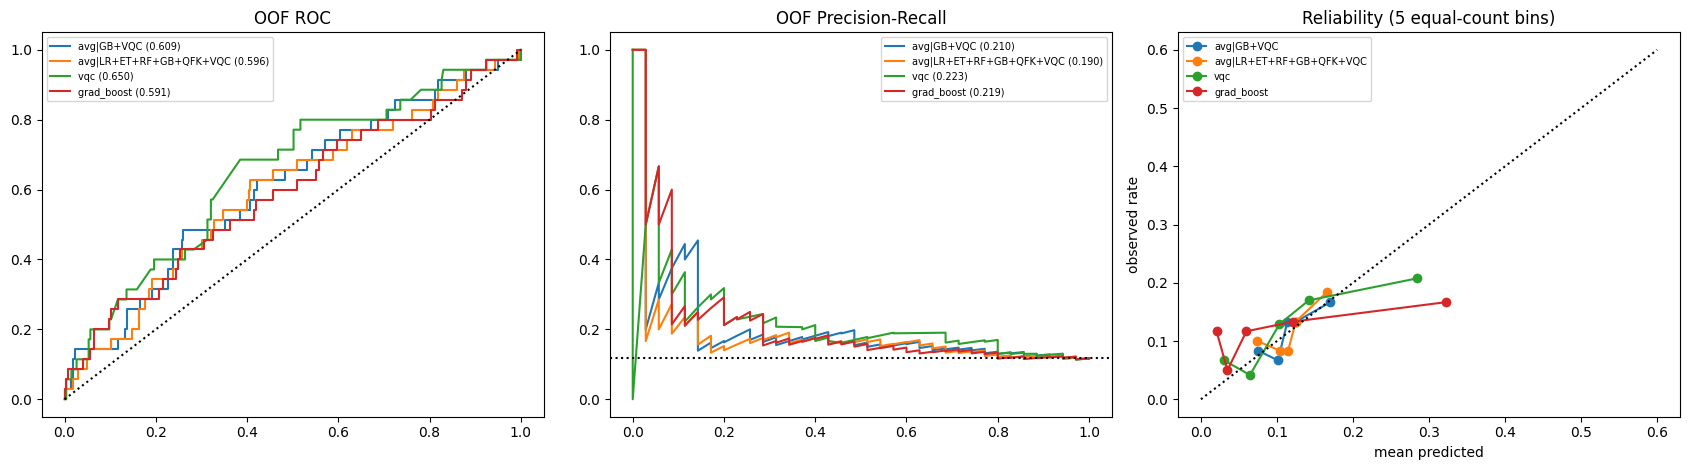

pooled OOF (300 rows, top-30 cut) for the final model: {'k': 30.0, 'precision_at_k': 0.1667, 'recall_at_k': 0.1429, 'roc_auc': 0.6092, 'pr_auc': 0.2098, 'brier': 0.1008, 'logloss': 0.3526, 'ece': 0.0147, 'cal_slope': 1.1121, 'cal_intercept': 0.2158}


In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve

def pooled_first_repeat(store, model, n):
    p = np.full(n, np.nan)
    for te, pp in store["RepStratKFold5"][model][:5]:
        p[te] = pp
    return p

show = list(dict.fromkeys([FINAL_VARIANT, ALL_ENS, bq, bc]))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for m in show:
    p = pooled_first_repeat(cv_oof, m, len(y_train))
    fpr, tpr, _ = roc_curve(y_train, p); pr, rc, _ = precision_recall_curve(y_train, p)
    ax[0].plot(fpr, tpr, label=f"{m} ({roc_auc_score(y_train, p):.3f})")
    ax[1].plot(rc, pr, label=f"{m} ({average_precision_score(y_train, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("OOF ROC"); ax[0].legend(fontsize=7)
ax[1].axhline(y_train.mean(), color="k", ls=":"); ax[1].set_title("OOF Precision-Recall"); ax[1].legend(fontsize=7)
for m in show:
    p = pooled_first_repeat(cv_oof, m, len(y_train))
    fr, mp = calibration_curve(y_train, p, n_bins=5, strategy="quantile")
    ax[2].plot(mp, fr, "o-", label=m)
ax[2].plot([0, 0.6], [0, 0.6], "k:"); ax[2].set_title("Reliability (5 equal-count bins)")
ax[2].set_xlabel("mean predicted"); ax[2].set_ylabel("observed rate"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT_DIR / "validation_diagnostics.png", dpi=130); plt.show()

oof_final = pooled_first_repeat(cv_oof, FINAL_VARIANT, len(y_train))
print("pooled OOF (300 rows, top-30 cut) for the final model:",
      {k: round(float(v), 4) for k, v in evaluate(y_train, oof_final, ids_train, topk=30).items()})

## Cell 12 — FINAL: fit on all 300 training rows, predict the test customers ONCE, rank, save

* Refuses to run if the test file overlaps train (see Cell 2): scoring rows the model was trained on is meaningless.
* Test labels, if present, are ignored. No refitting / re-tuning happens after this cell.
* Probabilities are rounded to 6 dp; the ranking uses exactly the saved numbers, ties → lower `customer_id`.

In [27]:


assert test_features.notna().all().all(), "missing values in test features"
final_system = HybridEnsembleSystem(fast=False).fit(X_train, y_train)    # all training rows
pred_all = final_system.predict_all(test_features)                       # the single prediction pass
prob = np.clip(np.round(pred_all[FINAL_VARIANT], 6), 1e-6, 1 - 1e-6)

order = rank_order(prob, test_raw[ID].values)
ranked = pd.DataFrame({ID: test_raw[ID].values[order], "probability": prob[order]})
ranked["rank"] = np.arange(1, len(ranked) + 1)
ranked["top10"] = ranked["rank"] <= TOPK
assert ranked[ID].is_unique and len(ranked) == len(test_raw)

ranked.to_csv(OUT_DIR / "predictions_ranked.csv", index=False)
ranked[[ID, "probability"]].sort_values(ID).to_csv(OUT_DIR / "submission.csv", index=False)
members_only = {k: np.round(v, 6) for k, v in pred_all.items() if k in BASE_NAMES or k == FINAL_VARIANT}
pd.DataFrame({ID: test_raw[ID].values, **members_only}).to_csv(OUT_DIR / "member_probabilities_test.csv", index=False)

print(f"final model: {FINAL_VARIANT} | mean predicted prob = {prob.mean():.3f} (train base rate {y_train.mean():.3f})")
print("\nTOP 10 customers:\n", ranked.head(TOPK).to_string(index=False))

final model: avg|GB+VQC | mean predicted prob = 0.119 (train base rate 0.117)

TOP 10 customers:
 customer_id  probability  rank  top10
      C0297     0.527943     1   True
      C0263     0.497782     2   True
      C0073     0.404334     3   True
      C0011     0.391731     4   True
      C0107     0.382222     5   True
      C0017     0.371492     6   True
      C0311     0.298679     7   True
      C0255     0.290453     8   True
      C0151     0.290304     9   True
      C0281     0.275728    10   True
